# Accuracy and latency

[05_02](05_02_run_vlm.ipynb) ran the model as the paper does and recorded answers and frame times.
First set its accuracy against the paper's own figure and against experiment 04.
Then compare the selectors on accuracy and read time, as [04_02](../04/04_02_accuracy_latency.ipynb) did.

A condition is a method and a requested fraction of the projection weights. `Dense` uses every row.

In [1]:
from scipy.stats import bootstrap

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

## 1. Data

`answers.csv` has one row per question and condition; `correct` says whether the answer was right.
`frame_times.csv` has one row per recorded frame and condition, with times in ms.

In [2]:
answers     = pd.read_csv("answers.csv")
frame_times = pd.read_csv("frame_times.csv")

## 2. Intervals

Every interval below is a 95% BCa bootstrap with 10,000 resamples, as in the paper.

In [3]:
def interval(values, statistic):
    """Return the 95% BCa bootstrap interval of a statistic: (low, high)."""

    result = bootstrap(
        (values,),
        statistic,
        confidence_level = 0.95,
        n_resamples      = 10_000,
        method           = "BCa",
        rng              = 0,
    )

    return result.confidence_interval.low, result.confidence_interval.high

## 3. Accuracy

Accuracy is the percentage of right answers of a condition.

In [4]:
records = []

for (method, fraction), rows in answers.groupby(["method", "fraction"], sort=False):
    scores    = 100.0 * rows.correct.to_numpy()
    low, high = interval(scores, np.mean)

    records.append({
        "method"        : method,
        "fraction"      : fraction,
        "accuracy"      : scores.mean(),
        "accuracy_low"  : low,
        "accuracy_high" : high,
    })

accuracy = pd.DataFrame(records)
accuracy = accuracy.set_index(["method", "fraction"])

## 4. Against the paper

Figure 6 of the paper has a panel for this model and benchmark, measured on a Jetson Orin Nano.
It plots accuracy at sparsity 0% to 70%, and its sparsity is $1 - f$ for a requested fraction $f$.
Its `Baseline` is `Top-R` here and its `Ours` is `Paper greedy`.

The values below are the coordinates of the points of that panel in the PDF.
The paper evaluates on the 385 videos outside its calibration set; 05_02 on 100 of them.

In [5]:
# Accuracy in the paper (%), by requested fraction
paper = pd.DataFrame(
    {
        "Top-R"        : [53.29, 53.15, 52.33, 52.33, 51.99, 49.73, 48.29, 47.67],
        "Paper greedy" : [53.29, 52.67, 52.33, 51.03, 50.07, 49.79, 47.33, 45.89],
    },
    index = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3],
)

Experiment 04 answered the same questions.
There every projection read the same fraction of its rows, all in checkpoint order.

In [6]:
answers_04 = pd.read_csv("../04/answers.csv")

# (method, fraction) -> accuracy in experiment 04 (%)
accuracy_04 = 100.0 * answers_04.groupby(["method", "fraction"]).correct.mean()

The accuracy of the paper's two methods at the fractions that 05_02 ran:

In [7]:
records = []

for method in paper.columns:
    for fraction, row in accuracy.loc[method].iterrows():
        records.append({
            "method"   : method,
            "fraction" : fraction,

            "paper" : paper.loc[fraction, method],
            "04"    : accuracy_04[(method, fraction)],

            "here" : row.accuracy,
            "low"  : row.accuracy_low,
            "high" : row.accuracy_high,
        })

comparison = pd.DataFrame(records)
comparison = comparison.set_index(["method", "fraction"])

comparison.round(1)

paper    04  here   low  high
method       fraction                               
Top-R        0.3        47.7  43.2  47.1  42.2  51.9
             0.5        49.7  48.6  49.4  44.5  54.2
             0.7        52.3  50.9  51.4  46.5  56.3
Paper greedy 0.3        45.9  33.5  46.0  41.2  50.9
             0.5        49.8  41.2  49.4  44.5  54.2
             0.7        51.0  47.8  50.6  45.8  55.5

One panel per method. Each line runs from the smallest fraction up to `Dense` at 100%.
Vertical bars are the accuracy intervals of 05_02.

In [8]:
colors = {
    "Top-R"        : "#2a78d6",
    "Paper greedy" : "#eb6834",
    "Tiles"        : "#1baf7a",
}

markers = {
    "Top-R"        : "o",
    "Paper greedy" : "s",
    "Tiles"        : "^",
}

In [9]:
def draw_paper(ax, method):
    values = paper[method]

    ax.plot(
        100 * values.index,
        values,
        label = "Paper",

        color           = "gray",
        linestyle       = "--",
        marker          = "o",
        markerfacecolor = "white",
    )

In [10]:
def draw_04(ax, method):

    # The fractions of the method, then Dense at 100%
    values = pd.concat([accuracy_04.loc[method], accuracy_04.loc["Dense"]])

    ax.plot(
        100 * values.index,
        values,
        label = "Experiment 04",

        color     = colors[method],
        linestyle = ":",
        marker    = "x",
    )

In [11]:
def draw_here(ax, method):

    # The fractions of the method, then Dense at 100%
    rows  = pd.concat([accuracy.loc[method], accuracy.loc["Dense"]])
    below = rows.accuracy - rows.accuracy_low
    above = rows.accuracy_high - rows.accuracy

    ax.errorbar(
        100 * rows.index,
        rows.accuracy,
        yerr  = [below, above],
        label = "Experiment 05",

        color      = colors[method],
        marker     = markers[method],
        markersize = 8,
        linewidth  = 2,
        capsize    = 3,
    )

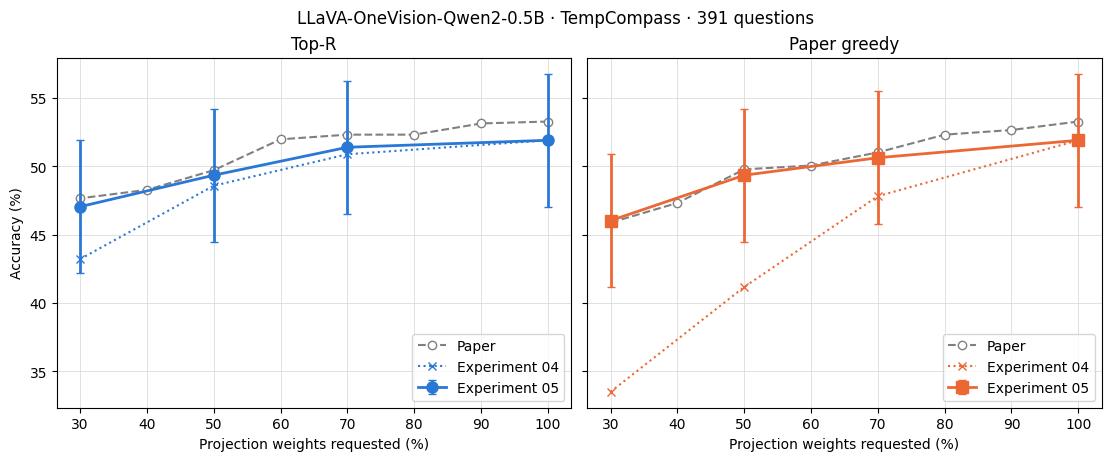

In [12]:
fig, axes = plt.subplots(
    1, 2,
    figsize = (11, 4.5),
    sharey  = True,
    layout  = "constrained",
)

for ax, method in zip(axes, paper.columns):
    draw_paper(ax, method)
    draw_04(ax, method)
    draw_here(ax, method)

    ax.set(
        title  = method,
        xlabel = "Projection weights requested (%)",
    )

    ax.grid(color="gainsboro", linewidth=0.6)
    ax.legend(loc="lower right")

axes[0].set_ylabel("Accuracy (%)")

questions = answers.question_id.nunique()
fig.suptitle(f"LLaVA-OneVision-Qwen2-0.5B · TempCompass · {questions} questions")

plt.show()

## 5. Time per frame

For one frame, `selection_ms` is the time the selectors of all projections take
and `io_ms` the time to read the selected rows from flash.
Their sum, `load_ms`, is how long the frame waits for its weights.
Take the median of each over the recorded frames.

In [13]:
frame_times["load_ms"] = frame_times.selection_ms + frame_times.io_ms

In [14]:
records = []

for (method, fraction), rows in frame_times.groupby(["method", "fraction"], sort=False):
    low, high = interval(rows.load_ms.to_numpy(), np.median)

    records.append({
        "method"       : method,
        "fraction"     : fraction,
        "selection_ms" : rows.selection_ms.median(),
        "io_ms"        : rows.io_ms.median(),
        "load_ms"      : rows.load_ms.median(),
        "load_low"     : low,
        "load_high"    : high,
    })

latency = pd.DataFrame(records)
latency = latency.set_index(["method", "fraction"])

## 6. Summary

In [15]:
summary = accuracy.join(latency)
summary.round(1)

accuracy  accuracy_low  accuracy_high  selection_ms  \
method       fraction                                                        
Dense        1.0           51.9          47.1           56.8           4.3   
Top-R        0.3           47.1          42.2           51.9          40.4   
             0.5           49.4          44.5           54.2          40.6   
             0.7           51.4          46.5           56.3          40.8   
Paper greedy 0.3           46.0          41.2           50.9          98.6   
             0.5           49.4          44.5           54.2         102.2   
             0.7           50.6          45.8           55.5         106.5   
Tiles        0.3           46.0          41.2           50.9           6.9   
             0.5           49.1          44.2           54.0           6.9   
             0.7           51.2          46.3           56.0           6.8   

                        io_ms  load_ms  load_low  load_high  
method       fraction                                        
Dense        1.0        262.0    266.3     265.5      269.3  
Top-R        0.3        861.5    902.0     896.4      904.6  
             0.5       1041.1   1081.6    1076.5     1084.7  
             0.7       1004.6   1045.5    1042.7     1047.3  
Paper greedy 0.3        109.7    208.5     208.1      209.3  
             0.5        156.2    258.7     258.0      259.0  
             0.7        200.1    307.8     306.5      308.9  
Tiles        0.3        109.9    116.8     116.6      116.9  
             0.5        156.4    163.2     163.0      163.5  
             0.7        196.6    203.4     203.2      203.7

## 7. Plot

Each line connects the three fractions of one method; the label beside a point gives the fraction.
The dotted lines cross at `Dense`: points to their right take longer than reading every row.

Left: read time only. Right: selection and read time. The time axes are logarithmic.

The accuracy intervals of the ten conditions are almost equally wide (percentage points):

In [16]:
widths = summary.accuracy_high - summary.accuracy_low

widths.agg(["min", "max"]).round(2)

min    9.72
max    9.72
dtype: float64

So each panel shows one interval of the average width as a scale, the gray bar,
instead of a bar at every point.

In [17]:
# Half the average width (percentage points)
half_width = widths.mean() / 2

In [18]:
# The fraction label of a point sits beside it:
# (horizontal alignment, vertical alignment, points right and up from the point).
# Paper and Tiles lie close together, so their labels take opposite sides.
anchors = {
    "Top-R"        : ("left",  "top",    ( 5, -4)),
    "Paper greedy" : ("left",  "top",    ( 5, -4)),
    "Tiles"        : ("right", "bottom", (-5,  4)),
}

In [19]:
def draw_dense(ax, column):
    dense = summary.loc[("Dense", 1.0)]

    ax.axvline(dense[column],  color="gray", linestyle=":", linewidth=1)
    ax.axhline(dense.accuracy, color="gray", linestyle=":", linewidth=1)

    ax.plot(
        dense[column],
        dense.accuracy,
        label = "Dense",

        color     = "black",
        linestyle = "none",
        marker    = "D",
    )

In [20]:
SCALE_MS = 450  # Where the scale stands on the time axes (ms): in the gap between the methods

def draw_scale(ax):
    """Draw one accuracy interval as a scale for the points of a panel."""

    # Halfway between the lowest and the highest accuracy
    middle = (summary.accuracy.min() + summary.accuracy.max()) / 2

    # A vertical line with a short dash at both ends
    ax.plot(
        [SCALE_MS, SCALE_MS],
        [middle - half_width, middle + half_width],

        color  = "dimgray",
        marker = "_",
    )

    ax.annotate(
        f"95% interval\nof each point:\n±{half_width:.1f}",
        (SCALE_MS, middle),
        xytext     = (8, 0),
        textcoords = "offset points",
        va         = "center",
        color      = "dimgray",
        fontsize   = 8,
    )

In [21]:
def draw_method(ax, column, method):
    rows = summary.loc[method]

    ax.plot(
        rows[column],
        rows.accuracy,
        label = method,

        color      = colors[method],
        marker     = markers[method],
        markersize = 8,
        linewidth  = 2,
    )

    # Fraction labels
    ha, va, shift = anchors[method]

    for fraction, row in rows.iterrows():
        ax.annotate(
            f"{fraction:.0%}",
            (row[column], row.accuracy),
            xytext     = shift,
            textcoords = "offset points",
            ha         = ha,
            va         = va,
            color      = "dimgray",
            fontsize   = 8,
        )

In [22]:
TICKS = [100, 200, 400, 800]  # Ticks of the time axes (ms)

def draw_panel(ax, column, label):
    draw_dense(ax, column)
    draw_scale(ax)

    for method in colors:
        draw_method(ax, column, method)

    ax.set(
        xscale = "log",
        xlabel = label,
    )

    # Plain numbers at the ticks instead of powers of ten
    ax.set_xticks(TICKS, labels=TICKS)
    ax.minorticks_off()

    # Room for the fraction labels
    ax.margins(x=0.1, y=0.08)

    ax.grid(color="gainsboro", linewidth=0.6)

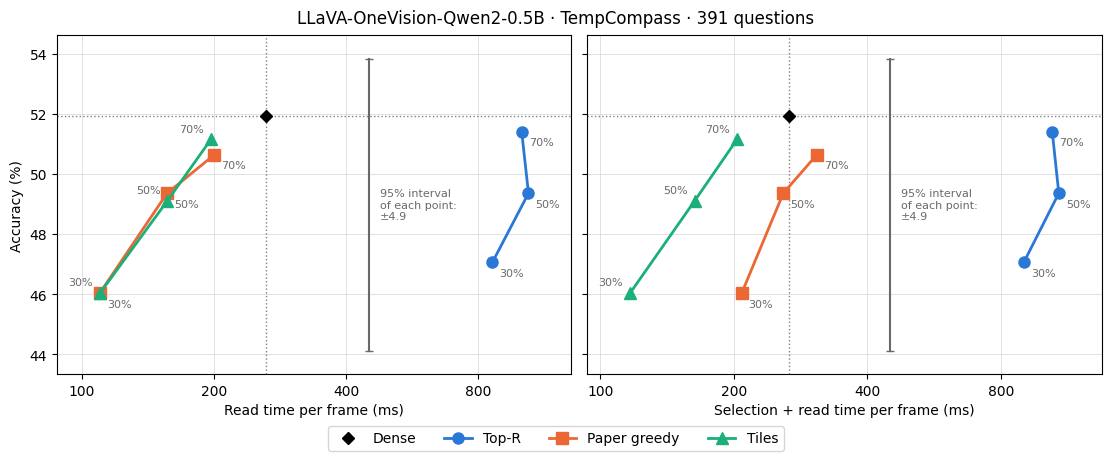

In [23]:
fig, (left, right) = plt.subplots(
    1, 2,
    figsize = (11, 4.5),
    sharey  = True,
    layout  = "constrained",
)

draw_panel(left,  "io_ms",   "Read time per frame (ms)")
draw_panel(right, "load_ms", "Selection + read time per frame (ms)")

left.set_ylabel("Accuracy (%)")

handles, labels = left.get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4)

fig.suptitle(f"LLaVA-OneVision-Qwen2-0.5B · TempCompass · {questions} questions")

plt.show()